# Step 2 — Preprocessing, EDA & Feature Engineering
**Tech Fem · SIC Capstone · Crude Oil Market & Inventory Forecasting**

**Input:** `data/crude_weekly.csv` (output of step 1: one row per week, weeks end on Friday).
**Output (in `data/processed/`):**
- `crude_weekly_full` (.csv + .parquet): every week since 1991. Series that started later keep their early values empty.
- `crude_weekly_complete` (.csv + .parquet): starts when the *latest* series starts, with no missing values at all.

**Plan**
1. Data quality: types, wrong values, missing values, outliers (numbers + charts)
2. Validate the outliers against real-world events and flag them
3. Fill the gaps in the middle of the series
4. Exploratory data analysis (EDA)
5. Feature engineering
6. Build the two datasets
7. Integrity checks and saving

> Put this notebook in the same main folder as `step1_data_acquisition.py`. Needs `pandas`, `numpy`, `matplotlib` and `pyarrow` (for parquet).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_FILE = Path("data/crude_weekly.csv")
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "crude_stocks_ex_spr"   # the stock level; the model predicts its weekly change
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 150)

raw = pd.read_csv(DATA_FILE)
print(raw.shape)
raw.head()

(1864, 14)


,date,crude_stocks_ex_spr,crude_production,crude_imports,crude_exports,refinery_net_input,refinery_utilisation,cushing_stocks,spr_stocks,gasoline_stocks,distillate_stocks,wti_price,brent_price,usd_index
0,1991-01-04,307542,7481.0,5536.0,NaN,12307,80.0,NaN,585692,221194.0,129423,26.38,26.07,NaN
1,1991-01-11,308440,7475.0,4866.0,NaN,12346,80.0,NaN,585691,217923.0,126956,27.55,25.33,NaN
2,1991-01-18,307051,7461.0,5053.0,NaN,12581,82.0,NaN,585691,216098.0,117980,26.85,25.86,NaN
3,1991-01-25,307043,7219.0,5122.0,NaN,12757,83.0,NaN,585692,219581.0,115089,24.08,20.77,NaN
4,1991-02-01,310149,7477.0,6212.0,NaN,12814,83.0,NaN,585692,222223.0,110890,21.41,20.72,NaN


## 1. Data quality

### 1.1 Data types and values stored as text
A CSV file is plain text. When pandas reads it, it guesses each column's type. If even **one** cell in a column is not a clean number, for example `"1,234"` (thousands comma) or `"--"`, `"W"`, `"NA"` (symbols EIA uses for "no data", "not applicable", "withheld"), the **whole column** becomes text (`object`). You cannot average, plot or model text, so we:
1. remove thousands commas,
2. turn EIA's "no data" symbols into proper missing values (`NaN`),
3. convert every column to a real number type (`float64`).

The table shows each column's type before the fix and how many cells were not valid numbers.

In [2]:
df = raw.copy()
value_cols = [c for c in df.columns if c != "date"]
NO_DATA_SYMBOLS = ["", "-", "--", "NA", "N/A", "W", ".", "nan", "None"]

type_report = []
for col in value_cols:
    text = df[col].astype(str).str.replace(",", "", regex=False).str.strip()
    numbers = pd.to_numeric(text.mask(text.isin(NO_DATA_SYMBOLS)), errors="coerce")
    type_report.append({
        "column": col,
        "type_before": str(raw[col].dtype),
        "non_numeric_cells": int((numbers.isna() & raw[col].notna()).sum()),
    })
    df[col] = numbers.astype("float64")

type_report = pd.DataFrame(type_report).set_index("column")
type_report["type_after"] = df[value_cols].dtypes.astype(str)
type_report

,type_before,non_numeric_cells,type_after
column,,,
crude_stocks_ex_spr,int64,0,float64
crude_production,float64,0,float64
crude_imports,float64,0,float64
crude_exports,float64,0,float64
refinery_net_input,int64,0,float64
refinery_utilisation,float64,0,float64
cushing_stocks,float64,0,float64
spr_stocks,int64,0,float64
gasoline_stocks,float64,0,float64


### 1.2 Dates: wrong, duplicated or missing weeks
Every row must be one week, labelled by the Friday the week ends on. We check that:
- every date can be read as a date,
- no week appears twice (if one does, we keep the last copy, which is the most recent download),
- every date is a Friday,
- no week is missing from the calendar. Missing weeks are added back as empty rows, so a gap stays visible and can be filled in step 3.

In [3]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Unreadable dates :", df["date"].isna().sum())
df = df.dropna(subset=["date"]).sort_values("date")
print("Duplicated dates :", df["date"].duplicated().sum())
df = df.drop_duplicates("date", keep="last").set_index("date")
print("All Fridays      :", bool((df.index.dayofweek == 4).all()))

calendar = pd.date_range(df.index.min(), df.index.max(), freq="W-FRI")
print("Missing weeks    :", len(calendar.difference(df.index)))
df = df.reindex(calendar)
df.index.name = "date"
print("Final shape      :", df.shape, "|", df.index.min().date(), "->", df.index.max().date())

Unreadable dates : 0
Duplicated dates : 0
All Fridays      : True
Missing weeks    : 0
Final shape      : (1864, 13) | 1991-01-04 -> 2026-09-18


### 1.3 Units and impossible values
**Units.** EIA reports Cushing stocks in *thousand* barrels (roughly 20,000–70,000). If the values look like *million* barrels (below 1,000), we convert them so every stock column uses the same unit.

**Impossible values.** Some values cannot exist in the real world, so they must be data errors:
- stocks, production, imports, exports and refinery input can't be **negative**,
- refinery utilisation is a percentage of capacity, so it must stay between 0 and ~100 (we allow up to 105 for rounding),
- Brent and the dollar index are always positive. WTI *did* go negative for one day (20 April 2020), so we only reject extreme values (below −50 or above 250 USD).

Any impossible value is turned into `NaN` (treated as missing) and filled later together with the other gaps. The summary shows the min / median / max of every column, which is a quick way to spot wrong units or strange values by eye.

In [4]:
if df["cushing_stocks"].median() < 1_000:
    df["cushing_stocks"] *= 1_000
    print("cushing_stocks converted from million to thousand barrels")

INF = np.inf
RULES = {  # column: (lowest possible, highest possible)
    "crude_stocks_ex_spr": (0, INF), "crude_production": (0, INF), "crude_imports": (0, INF),
    "crude_exports": (0, INF), "refinery_net_input": (0, INF), "refinery_utilisation": (0, 105),
    "cushing_stocks": (0, INF), "spr_stocks": (0, INF), "gasoline_stocks": (0, INF),
    "distillate_stocks": (0, INF), "wti_price": (-50, 250), "brent_price": (0, 250),
    "usd_index": (0, 300),
}
impossible = {}
for col, (low, high) in RULES.items():
    bad = (df[col] < low) | (df[col] > high)
    impossible[col] = int(bad.sum())
    df.loc[bad, col] = np.nan

summary = df.describe().T[["min", "50%", "max"]].round(1)
summary["impossible_values_removed"] = pd.Series(impossible)
summary

,min,50%,max,impossible_values_removed
crude_stocks_ex_spr,247323.0,326811.5,540722.0,0
crude_production,3813.0,6598.0,13947.0,0
crude_imports,4278.0,7870.0,11324.0,0
crude_exports,10.0,104.0,6438.0,0
refinery_net_input,9903.0,15174.0,17981.0,0
refinery_utilisation,56.0,90.3,100.5,0
cushing_stocks,11677.0,32196.5,69420.0,0
spr_stocks,284552.0,621304.0,726617.0,0
gasoline_stocks,178739.0,215360.5,263234.0,0
distillate_stocks,87153.0,125959.0,179977.0,0


### 1.4 Missing values
We split missing values into three kinds, because each one is handled differently:
- **leading**: before a series starts (e.g. Cushing stocks start in 2004, the dollar index in 2006). These are *not errors*: the data simply didn't exist yet. They are handled with the two output files (section 6).
- **inside gaps**: holes in the middle of a series (missing weeks, removed impossible values). These are filled in section 3.
- **trailing**: the newest week(s) not yet published for a series.

The chart shows missing values in black over time: a black block at the left means a series started later.

,first_value,leading,inside_gaps,trailing,missing_%
column,,,,,
crude_stocks_ex_spr,1991-01-04,0,0,0,0.0
crude_production,1991-01-04,0,0,0,0.0
crude_imports,1991-01-04,0,0,0,0.0
crude_exports,1991-02-08,5,0,0,0.3
refinery_net_input,1991-01-04,0,0,0,0.0
refinery_utilisation,1991-01-04,0,0,0,0.0
cushing_stocks,2004-04-09,692,0,0,37.1
spr_stocks,1991-01-04,0,0,0,0.0
gasoline_stocks,1991-01-04,0,0,0,0.0


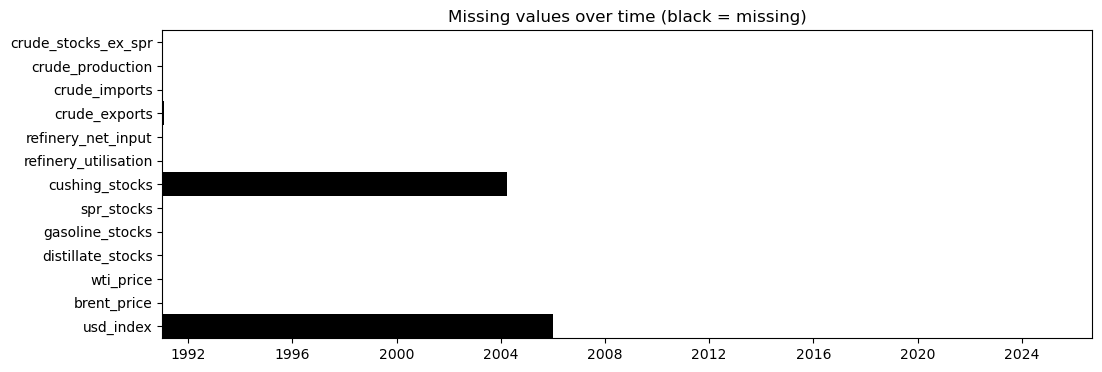

In [5]:
def missing_summary(frame):
    rows = []
    for col, s in frame.items():
        first, last = s.first_valid_index(), s.last_valid_index()
        rows.append({"column": col, "first_value": first.date(),
                     "leading": int(s[:first].isna().sum()),
                     "inside_gaps": int(s[first:last].isna().sum()),
                     "trailing": int(s[last:].isna().sum()),
                     "missing_%": round(100 * s.isna().mean(), 1)})
    return pd.DataFrame(rows).set_index("column")

display(missing_summary(df))

fig, ax = plt.subplots(figsize=(12, 4))
x0, x1 = mdates.date2num(df.index[0]), mdates.date2num(df.index[-1])
ax.imshow(df.isna().T, aspect="auto", cmap="Greys", interpolation="none",
          extent=[x0, x1, len(df.columns), 0])
ax.set_yticks(np.arange(len(df.columns)) + 0.5, df.columns)
ax.xaxis_date()
ax.grid(False)
ax.set_title("Missing values over time (black = missing)")
plt.show()

### 1.5 Outliers: statistical detection
**Why weekly changes, not levels?** Levels trend over decades: U.S. production today is about double what it was in 2010, and that is *normal*, not an outlier. What we really care about is a week that jumps unusually far. So we look for outliers in the **week-to-week change** of each series.

**The rule (Tukey's fences, made time-aware).** For each week we look at the changes in the *previous 3 years* (156 weeks) and compute the middle 50% range (IQR = 75th percentile − 25th percentile). A change is flagged when it is more than **3 × IQR** below the 25th or above the 75th percentile. 3 × IQR is the classic threshold for *extreme* outliers.
- Using the previous 3 years (not the whole history) lets "normal" adapt. For example, exports became far more volatile after 2016.
- The IQR is never allowed to be smaller than the series' *typical* move (its full-history IQR, or the median size of a non-zero change, whichever is bigger). Production before Nov 2024 and exports before 2016 were published as flat steps, where most weekly changes are exactly 0. Without this floor, every small step would be flagged.
- Only past weeks are used, so no information from the future leaks into the flags.

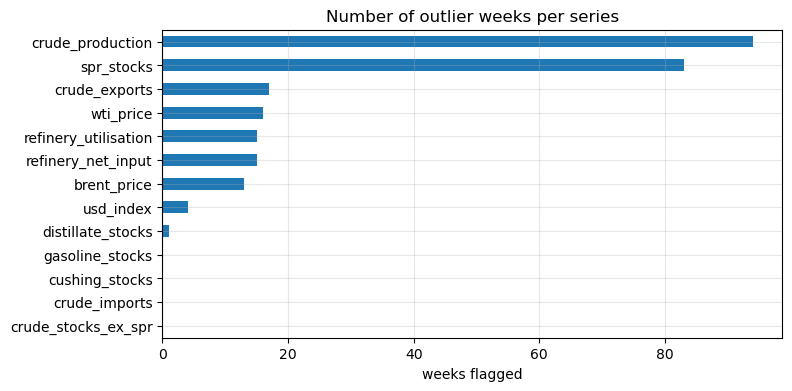

In [6]:
changes = df.diff()

def flag_outliers(x, window=156, k=3):
    q1 = x.rolling(window, min_periods=52).quantile(0.25)
    q3 = x.rolling(window, min_periods=52).quantile(0.75)
    typical = max(x.quantile(0.75) - x.quantile(0.25), x[x != 0].abs().median())
    iqr = np.maximum(q3 - q1, typical)
    return (x < q1 - k * iqr) | (x > q3 + k * iqr)

outliers = changes.apply(flag_outliers)
ax = outliers.sum().sort_values().plot.barh(figsize=(8, 4), title="Number of outlier weeks per series")
ax.set_xlabel("weeks flagged")
plt.show()

## 2. Validate the outliers with real-world events
A statistical outlier is not automatically a *mistake*. Wars, crises and hurricanes really do move oil markets, and a model must learn from those weeks. So we compare the flagged weeks with a list of known events. The windows are approximate; edit them if you find better dates.

- **Outlier inside a known event** → real market behaviour. We **keep** the value and **flag** the week.
- **Outlier outside any event** → listed below for a manual look. With EIA data these are usually still real (tanker timing, EIA re-benchmarking production estimates), so we keep them too. Only *impossible* values (section 1.3) were removed.

In [7]:
EVENTS = {  # name: (start, end); None = still ongoing
    "Gulf War":                           ("1991-01-01", "1991-03-31"),
    "Hurricanes Katrina & Rita":          ("2005-08-26", "2005-10-31"),
    "Hurricanes Gustav & Ike":            ("2008-08-29", "2008-10-10"),
    "2008 financial crisis":              ("2008-09-15", "2009-06-30"),
    "Hurricane Harvey":                   ("2017-08-25", "2017-10-06"),
    "COVID-19 demand collapse":           ("2020-03-01", "2020-07-31"),
    "Winter Storm Uri":                   ("2021-02-12", "2021-03-12"),
    "Hurricane Ida":                      ("2021-08-27", "2021-09-24"),
    "Russia-Ukraine war & SPR release":   ("2022-02-24", "2022-12-31"),
    "Israel-Iran 12-day war":             ("2025-06-13", "2025-06-27"),
    "2026 Iran war & Hormuz crisis":      ("2026-02-28", None),
}

event = pd.Series("", index=df.index, dtype=object)
for name, (start, end) in EVENTS.items():
    inside = (df.index >= pd.Timestamp(start)) & (df.index <= pd.Timestamp(end or df.index.max()))
    event[inside] = [name if e == "" else f"{e} + {name}" for e in event[inside]]
in_event = event != ""

validation = pd.DataFrame({"outlier_weeks": outliers.sum(),
                           "during_known_events": outliers[in_event].sum()})
validation["explained_%"] = (100 * validation["during_known_events"]
                             / validation["outlier_weeks"].replace(0, np.nan)).round(0)
display(validation)

flagged = outliers.stack()
flagged = flagged[flagged].index.to_frame(index=False, name=["date", "column"])
flagged["change"] = [changes.at[d, c] for d, c in zip(flagged["date"], flagged["column"])]
flagged["event"] = event.reindex(flagged["date"]).to_numpy()
print("Outliers per event:")
display(flagged[flagged["event"] != ""].groupby("event").size().sort_values(ascending=False))
print("Outliers outside known events (check manually):")
flagged[flagged["event"] == ""].sort_values("date").head(20)

,outlier_weeks,during_known_events,explained_%
crude_stocks_ex_spr,0,0,NaN
crude_production,94,14,15.0
crude_imports,0,0,NaN
crude_exports,17,2,12.0
refinery_net_input,15,11,73.0
refinery_utilisation,15,11,73.0
cushing_stocks,0,0,NaN
spr_stocks,83,46,55.0
gasoline_stocks,0,0,NaN
distillate_stocks,1,0,0.0


Outliers per event:


event
2026 Iran war & Hormuz crisis                      36
Russia-Ukraine war & SPR release                   19
COVID-19 demand collapse                           15
Hurricanes Katrina & Rita                          10
Hurricanes Gustav & Ike + 2008 financial crisis     9
Hurricane Harvey                                    8
Winter Storm Uri                                    8
2008 financial crisis                               5
Hurricane Ida                                       3
Hurricanes Gustav & Ike                             3
dtype: int64

Outliers outside known events (check manually):


,date,column,change,event
0,1992-08-28,crude_production,-442.0,
1,1992-10-16,spr_stocks,1864.0,
2,1993-04-30,spr_stocks,1645.0,
3,1993-07-30,crude_production,190.0,
4,1994-02-18,crude_production,-256.0,
5,1994-02-25,crude_production,246.0,
6,1994-03-18,spr_stocks,1976.0,
7,1994-04-22,crude_production,-419.0,
8,1994-04-29,crude_production,456.0,
9,1996-03-29,spr_stocks,-2495.0,


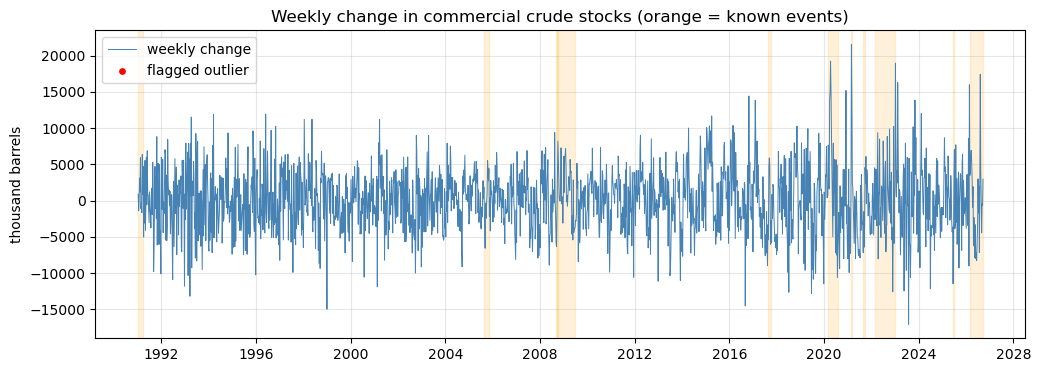

In [8]:
def shade_events(ax):
    for start, end in EVENTS.values():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end or df.index.max()), color="orange", alpha=0.15)

target_change = changes[TARGET]
fig, ax = plt.subplots()
ax.plot(target_change.index, target_change, lw=0.7, color="steelblue", label="weekly change")
ax.scatter(target_change.index[outliers[TARGET]], target_change[outliers[TARGET]],
           color="red", s=15, zorder=3, label="flagged outlier")
shade_events(ax)
ax.set_title("Weekly change in commercial crude stocks (orange = known events)")
ax.set_ylabel("thousand barrels")
ax.legend()
plt.show()

## 3. Fill the gaps in the middle
Only **inside gaps** are filled, using **time-based linear interpolation**: a missing week gets the value on the straight line between the week before and the week after. Stocks and prices move gradually from week to week, so this is a fair, neutral guess that doesn't invent new peaks or dips.
- **Leading** gaps (before a series starts) are **not** filled. Inventing 15 years of dollar index or Cushing stocks would be fake data. They are handled with two output files (section 6).
- **Trailing** gaps (the newest week not published yet for a series) are carried forward from the last known value, for at most 2 weeks. That's exactly what a forecaster would know in real time.

In [9]:
before = df.isna().sum()
df = df.interpolate(method="time", limit_area="inside").ffill(limit=2)
filled = (before - df.isna().sum()).rename("values_filled")
print(filled[filled > 0] if filled.any() else "No gaps needed filling.")
missing_summary(df)[["first_value", "leading", "inside_gaps", "trailing"]]

usd_index    1
Name: values_filled, dtype: int64


,first_value,leading,inside_gaps,trailing
column,,,,
crude_stocks_ex_spr,1991-01-04,0,0,0
crude_production,1991-01-04,0,0,0
crude_imports,1991-01-04,0,0,0
crude_exports,1991-02-08,5,0,0
refinery_net_input,1991-01-04,0,0,0
refinery_utilisation,1991-01-04,0,0,0
cushing_stocks,2004-04-09,692,0,0
spr_stocks,1991-01-04,0,0,0
gasoline_stocks,1991-01-04,0,0,0


## 4. Exploratory data analysis (EDA)
### 4.1 The big picture
Four panels showing how the market evolved since 1991, with known events shaded orange. Things to look for:
- **Stocks**: long swings plus a clear yearly rhythm, and spikes in the crisis gluts (e.g. 2016, 2020).
- **Prices**: crashes in 2008, 2014–2016 and 2020, and spikes around wars (2022, 2026).
- **Production & exports**: the shale boom after ~2011, and exports taking off after the export ban ended (Dec 2015).
- **Refinery utilisation**: repeated seasonal dips (maintenance) and sharp drops during hurricanes and COVID.

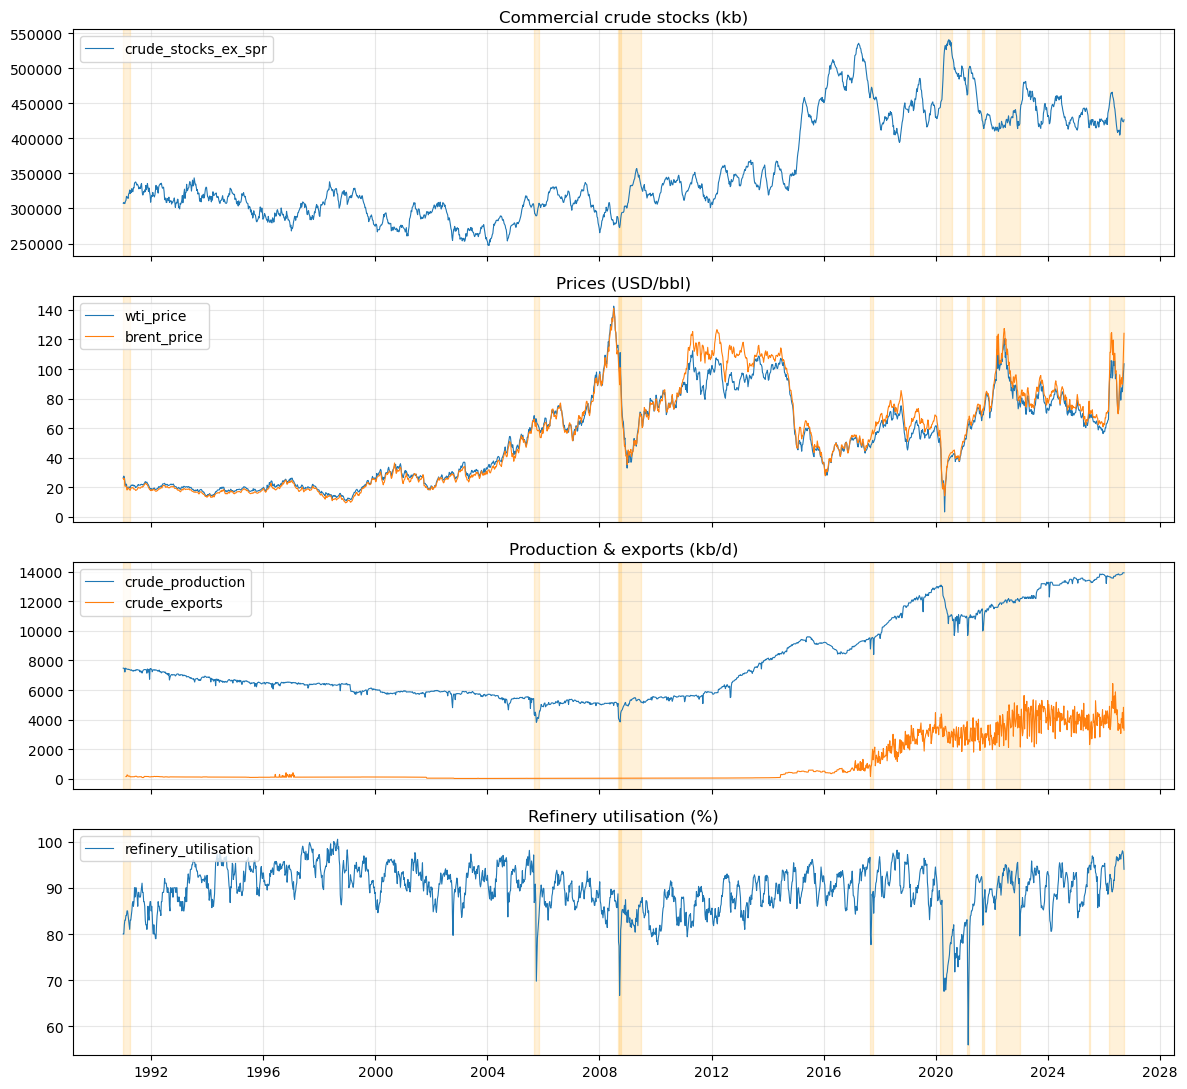

In [10]:
panels = [([TARGET], "Commercial crude stocks (kb)"),
          (["wti_price", "brent_price"], "Prices (USD/bbl)"),
          (["crude_production", "crude_exports"], "Production & exports (kb/d)"),
          (["refinery_utilisation"], "Refinery utilisation (%)")]
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, (cols, title) in zip(axes, panels):
    for col in cols:
        ax.plot(df.index, df[col], lw=0.8, label=col)
    shade_events(ax)
    ax.set_title(title)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 4.2 The target: size and seasonality
The model predicts the **weekly change in stocks** (a *build* if positive, a *draw* if negative).
- **Left**: how big weekly changes usually are. The centre shows normal weeks; the long tails are the rare shock weeks.
- **Right**: the average change by month. U.S. stocks usually **build in early spring** (refineries are in maintenance, so they use less crude) and **draw in summer** (refineries run hard for the driving season). A repeating pattern like this is why seasonal features and SARIMAX make sense.

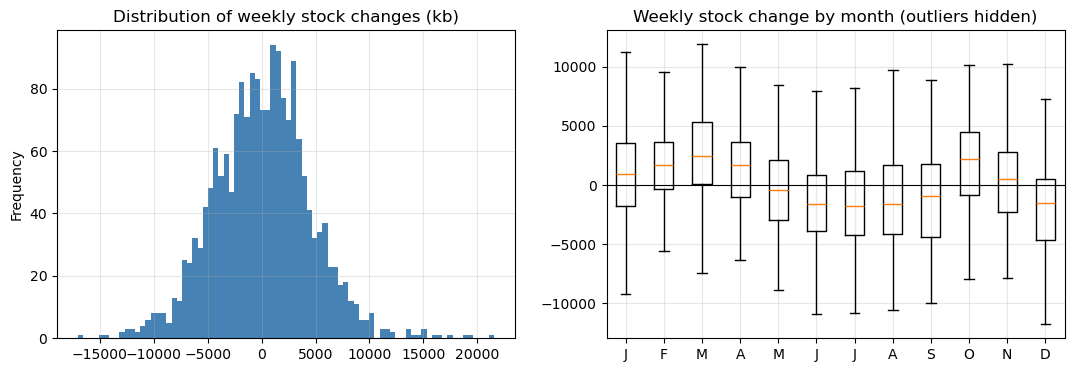

count     1863.0
mean        64.0
std       4495.0
min     -17049.0
25%      -2819.0
50%        118.0
75%       2860.0
max      21563.0
Name: crude_stocks_ex_spr, dtype: float64


In [11]:
stock_change = df[TARGET].diff()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
stock_change.plot.hist(bins=80, ax=a1, color="steelblue")
a1.set_title("Distribution of weekly stock changes (kb)")
by_month = [stock_change[stock_change.index.month == m].dropna() for m in range(1, 13)]
a2.boxplot(by_month, showfliers=False)
a2.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
a2.axhline(0, color="black", lw=0.8)
a2.set_title("Weekly stock change by month (outliers hidden)")
plt.show()
print(stock_change.describe().round(0))

### 4.3 Does the oil balance explain the stock change?
Physically, crude that enters the U.S. system but isn't used ends up in storage:

**implied change = 7 × (production + imports − exports − refinery input) − change in SPR**

(×7 converts barrels *per day* to barrels *per week*; SPR barrels are taken out because our target excludes the SPR.)

If the dots sit near the diagonal line, the flows explain the stock changes. Any distance from the line is EIA's "adjustment" (unaccounted-for crude), which grew in recent years. This tells us two things: the flows are the most important drivers, but they can't explain everything. That's why the target is hard to predict.

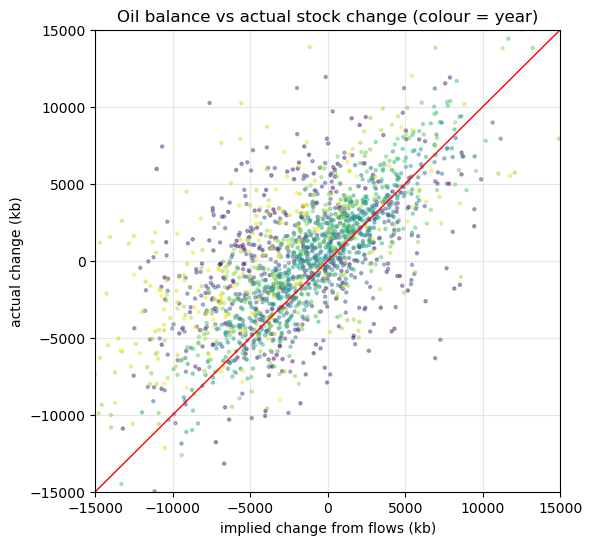

Correlation implied vs actual: 0.69


In [12]:
def implied_stock_change(frame):
    flows = (frame["crude_production"] + frame["crude_imports"]
             - frame["crude_exports"] - frame["refinery_net_input"])
    return 7 * flows - frame["spr_stocks"].diff()

implied = implied_stock_change(df)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(implied, stock_change, s=5, alpha=0.4, c=df.index.year, cmap="viridis")
lim = np.nanpercentile(np.abs(stock_change), 99.5)
ax.plot([-lim, lim], [-lim, lim], color="red", lw=1)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="implied change from flows (kb)",
       ylabel="actual change (kb)", title="Oil balance vs actual stock change (colour = year)")
plt.show()
print("Correlation implied vs actual:", round(implied.corr(stock_change), 2))

### 4.4 Relationships between variables
Correlating **levels** is misleading: any two series that both trend over 30 years look strongly related even if they aren't (spurious correlation). So we correlate **weekly changes**.
- **Heatmap**: which variables move together *in the same week*. Expected: crude imports up → stocks up; refinery input up → stocks down; WTI and Brent almost identical.
- **Bar chart**: how each variable's change *this week* correlates with the stock change *next week*. This is what matters for forecasting. Small values are normal for weekly oil data; even weak signals help when models combine them.

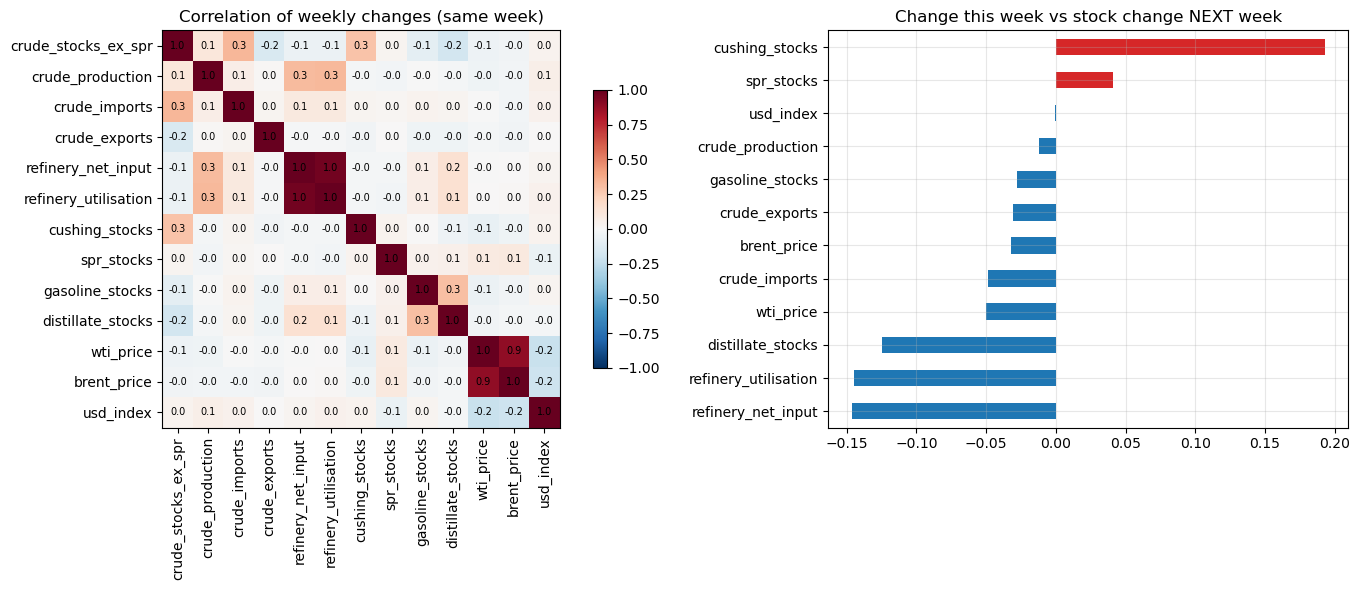

In [13]:
chg = df.diff()
corr = chg.corr()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
im = a1.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
a1.set_xticks(range(len(corr)), corr.columns, rotation=90)
a1.set_yticks(range(len(corr)), corr.columns)
a1.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        a1.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=a1, shrink=0.7)
a1.set_title("Correlation of weekly changes (same week)")

lead = chg.corrwith(chg[TARGET].shift(-1)).drop(TARGET).sort_values()
lead.plot.barh(ax=a2, color=np.where(lead > 0, "tab:red", "tab:blue"))
a2.set_title("Change this week vs stock change NEXT week")
plt.tight_layout()
plt.show()

### 4.5 The Brent–WTI spread and exports
When Brent (world price) is much higher than WTI (U.S. price), selling U.S. crude abroad is more profitable, so exports rise and U.S. stocks fall. We only look at weeks from 2016 on, because U.S. crude exports were legally restricted before that. An upward trend in the dots supports adding the **spread** as a feature.

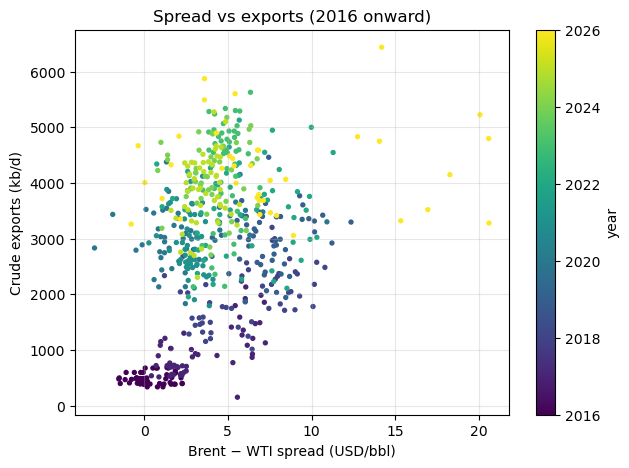

Correlation: 0.35


In [14]:
recent = df.loc["2016":]
spread = recent["brent_price"] - recent["wti_price"]
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(spread, recent["crude_exports"], s=8, c=recent.index.year, cmap="viridis")
fig.colorbar(sc, label="year")
ax.set(xlabel="Brent − WTI spread (USD/bbl)", ylabel="Crude exports (kb/d)",
       title="Spread vs exports (2016 onward)")
plt.show()
print("Correlation:", round(spread.corr(recent["crude_exports"]), 2))

## 5. Feature engineering
We add only features with a clear reason. **Leakage rule:** every value in a row must be known when that week's EIA report comes out (Wednesday). The model uses row *t* to predict **next week's** stock change, so the label is shifted one week forward.

| New column | What it is | Why we need it |
|---|---|---|
| `stocks_change` | this week's stock change | Our target variable, and also the most recent known value for the model. |
| `target_next_week_change` | next week's stock change | **The label the models learn to predict.** Shifting it forward guarantees no future information sits in the same row as the features. |
| `stocks_change_4wk_avg` | average change over the last 4 weeks | Smooths out noisy single weeks and shows the recent trend (building or drawing). |
| `spr_change` | weekly change in SPR stocks | SPR releases often end up in commercial tanks (e.g. 2022), which can explain commercial builds. |
| `implied_change` | the oil-balance estimate from section 4.3 | Packs the physical supply − demand story into one number. |
| `brent_wti_spread` | Brent − WTI | The export profitability signal from section 4.5. |
| `stocks_vs_5yr_avg` | stocks minus the average for the same week over the past 5 years | The industry's standard measure of "tight vs oversupplied". It also removes the normal seasonal level. |
| `week_sin`, `week_cos` | position in the year as a circle | Lets models see seasonality smoothly: week 52 sits next to week 1, which a plain week number (1…52) can't show. |
| `is_event`, `event_name` | inside a known event window (section 2) | For regime analysis: comparing model errors in normal vs crisis weeks. |
| `stocks_change_outlier` | 1 if this week's change was flagged in section 1.5 | Lets evaluation separate normal weeks from shock weeks. |

We deliberately do **not** add long lists of lags or rolling windows for every column. LightGBM and the LSTM can learn lag patterns themselves, and extra columns mostly add noise.

In [15]:
fe = df.copy()
fe["stocks_change"] = fe[TARGET].diff()
fe["target_next_week_change"] = fe["stocks_change"].shift(-1)
fe["stocks_change_4wk_avg"] = fe["stocks_change"].rolling(4).mean()
fe["spr_change"] = fe["spr_stocks"].diff()
fe["implied_change"] = implied_stock_change(fe)
fe["brent_wti_spread"] = fe["brent_price"] - fe["wti_price"]

same_week_past_years = pd.concat([fe[TARGET].shift(52 * k) for k in range(1, 6)], axis=1)
fe["stocks_vs_5yr_avg"] = fe[TARGET] - same_week_past_years.mean(axis=1, skipna=False)

week = fe.index.isocalendar().week.astype(float).to_numpy()
fe["week_sin"] = np.sin(2 * np.pi * week / 52.18)
fe["week_cos"] = np.cos(2 * np.pi * week / 52.18)

fe["is_event"] = in_event.astype(int)
fe["event_name"] = event.replace("", "none")
fe["stocks_change_outlier"] = outliers[TARGET].astype(int)

new_cols = [c for c in fe.columns if c not in df.columns]
fe[new_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stocks_change,1863.0,63.80,4495.25,-17049.00,-2819.00,118.00,2860.50,21563.00
target_next_week_change,1863.0,63.80,4495.25,-17049.00,-2819.00,118.00,2860.50,21563.00
stocks_change_4wk_avg,1860.0,62.94,2714.71,-7986.50,-1748.56,26.25,1715.25,15820.00
spr_change,1863.0,-161.64,1277.16,-9920.00,-1.00,0.00,150.00,4510.00
implied_change,1859.0,-1787.41,5040.25,-22741.00,-4877.50,-1614.00,1423.50,28266.00
brent_wti_spread,1864.0,2.02,5.51,-10.21,-1.57,-0.32,4.24,28.33
stocks_vs_5yr_avg,1604.0,11578.53,40127.35,-76582.40,-16320.90,5279.60,27485.60,146443.80
week_sin,1864.0,0.00,0.71,-1.00,-0.68,0.01,0.75,1.00
week_cos,1864.0,-0.00,0.71,-1.00,-0.74,-0.02,0.74,1.00
is_event,1864.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00


## 6. Build the two datasets
Different models need different things, so we keep two versions:

- **`crude_weekly_full`**: all weeks since 1991. Series that started later (Cushing 2004, dollar index 2006, …) stay empty before their start. Useful for models that only use the stock history (seasonal naive, SARIMAX on the target), and for LightGBM, which can handle missing values natively.
- **`crude_weekly_complete`**: starts on the first week where **every** series exists, and drops any row that is still incomplete. That includes the last week, whose "next week" label isn't known yet. Needed for models that can't accept missing values. The price: fewer years of history.

In [16]:
raw_cols = list(df.columns)
latest_start = df[raw_cols].apply(lambda s: s.first_valid_index()).max()
print("Series that start last:", df[raw_cols].apply(lambda s: s.first_valid_index()).idxmax(),
      "->", latest_start.date())

full = fe.copy()
complete = fe.loc[latest_start:].dropna()

print(f"full     : {len(full):>5} weeks  {full.index.min().date()} -> {full.index.max().date()}")
print(f"complete : {len(complete):>5} weeks  {complete.index.min().date()} -> {complete.index.max().date()}")

Series that start last: usd_index -> 2006-01-06
full     :  1864 weeks  1991-01-04 -> 2026-09-18
complete :  1080 weeks  2006-01-06 -> 2026-09-11


## 7. Integrity checks and saving
Before saving, we test that the data is correct and logical. Every check must return `True`:
- **structure**: dates sorted, unique, all Fridays, exactly 7 days apart; every column numeric (except the event name); no infinite values,
- **missing values**: none in `complete`; in `full`, only before a series starts (plus the unknown final label),
- **logic**: all physical limits from 1.3 respected, flags are only 0/1,
- **features are computed correctly**: stock change = difference of stock levels, label = the *next* week's change (no leakage), spread = Brent − WTI, implied change matches its formula.

If any check is `False`, the notebook stops with an error and nothing is saved.

In [17]:
def integrity_checks(d, allow_leading_missing):
    num = d.drop(columns="event_name")
    step = d.index.to_series().diff().dropna()
    c = {
        "dates sorted & unique": d.index.is_monotonic_increasing and d.index.is_unique,
        "all dates are Fridays": bool((d.index.dayofweek == 4).all()),
        "exactly 7 days between weeks": bool((step == pd.Timedelta(days=7)).all()),
        "all feature columns numeric": all(pd.api.types.is_numeric_dtype(t) for t in num.dtypes),
        "no infinite values": not np.isinf(num.to_numpy(dtype=float)).any(),
        "physical limits respected": all(d[k].dropna().between(lo, hi).all() for k, (lo, hi) in RULES.items()),
        "flags are 0/1": bool(d[["is_event", "stocks_change_outlier"]].isin([0, 1]).all().all()),
        "stocks_change = diff of stocks": np.allclose(d["stocks_change"].iloc[1:], d[TARGET].diff().iloc[1:], equal_nan=True),
        "label = next week's change": np.allclose(d["target_next_week_change"].iloc[:-1],
                                                  d["stocks_change"].shift(-1).iloc[:-1], equal_nan=True),
        "spread = brent - wti": np.allclose(d["brent_wti_spread"], d["brent_price"] - d["wti_price"], equal_nan=True),
        "implied_change formula": np.allclose(d["implied_change"].iloc[1:], implied_stock_change(d).iloc[1:], equal_nan=True),
    }
    if allow_leading_missing:
        after_start = {col: int(s[s.first_valid_index():].isna().sum()) for col, s in num.items()}
        after_start["target_next_week_change"] -= 1          # last label is unknown by definition
        c["no missing values after a series starts"] = all(v == 0 for v in after_start.values())
    else:
        c["no missing values"] = not d.isna().any().any()
    return pd.Series(c)

checks = pd.concat([integrity_checks(full, True), integrity_checks(complete, False)],
                   axis=1, keys=["full", "complete"], sort=False)
display(checks)
assert checks.fillna(True).all().all(), "Integrity check failed - fix before saving!"

,full,complete
dates sorted & unique,True,True
all dates are Fridays,True,True
exactly 7 days between weeks,True,True
all feature columns numeric,True,True
no infinite values,True,True
physical limits respected,True,True
flags are 0/1,True,True
stocks_change = diff of stocks,True,True
label = next week's change,True,True
spread = brent - wti,True,True


C:\Users\AL-OFQ\AppData\Local\Temp\ipykernel_8696\2186489656.py:29: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  assert checks.fillna(True).all().all(), "Integrity check failed - fix before saving!"


In [19]:
for name, data in {"crude_weekly_full": full, "crude_weekly_complete": complete}.items():
    data.to_csv(OUT_DIR / f"{name}.csv", date_format="%Y-%m-%d")
    data.to_parquet(OUT_DIR / f"{name}.parquet")
    reloaded = pd.read_csv(OUT_DIR / f"{name}.csv", index_col="date", parse_dates=True)
    same = reloaded.shape == data.shape and reloaded.isna().sum().sum() == data.isna().sum().sum()
    print(f"{name:24s} {data.shape}  saved as .csv + .parquet | reload check: {same}")

crude_weekly_full        (1864, 25)  saved as .csv + .parquet | reload check: True
crude_weekly_complete    (1080, 25)  saved as .csv + .parquet | reload check: True


## Summary
- Converted every column to a proper number type and turned EIA's "no data" symbols into missing values.
- Checked dates (duplicates, Fridays, missing weeks), units and physically impossible values.
- Flagged outliers in weekly changes and matched them to real events. Outliers were **kept**, because they are real market behaviour, and **flagged**.
- Filled only the gaps in the middle (time interpolation), and the newest 1–2 weeks by carrying the last value forward.
- EDA: trends, seasonality, the oil balance, correlations of changes, the spread vs exports.
- Added 12 new columns (11 features + the label), each with a clear purpose; the label is next week's stock change (no leakage).
- Saved `crude_weekly_full` and `crude_weekly_complete` as CSV and parquet after all integrity checks passed.

**Next:** send back the output tables and charts (type report, missing summary, outlier validation, integrity checks, and the figures) for the documentation and README.